### Statewide validation metrics — the Coast metric suite, applied to all of Texas

`validation_metrics_full_comparison.ipynb` answered review point 5 for the Coast zone:
correlation, peak, load factor, coincidence/diversity factor, load duration curve, diurnal
shape, seasonal bias, spatial-consistency proxy. This notebook recomputes **every one of those
metrics statewide**, with identical definitions, on the calibrated bus-level reconstruction of
all 6,717 Texas 7k buses against ERCOT's eight weather zones and system total.

Calibration is the per-zone fit from `zone_calibration.ipynb`
(`RES_z * res_z(t) + COM_z * com_z(t) + IND_z`), applied inside each ERCOT zone and then summed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

statewide_dir = Path("..")
exports_out_dir = statewide_dir / "exports"
metrics_dir = statewide_dir / "metrics"
repo_root = statewide_dir.resolve().parent
loadcurves = repo_root / "loadcurves"
FIG = repo_root / "latex_report" / "figures"

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#b8b7b2"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
mpl.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "grid.color": "#e8e7e3", "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white"})

AREA_TO_ERCOT = {"Coast": "COAST", "East": "EAST", "Far West": "FWEST", "North": "NORTH",
                 "North Central": "NCENT", "South": "SOUTH", "South Central": "SCENT", "West": "WEST"}
ZONES = list(AREA_TO_ERCOT.values())
MISMATCH = {"EAST", "NORTH"}

bus = pd.read_csv(statewide_dir / "bus_zone_master.csv", dtype={"COUNTYFP": str})
bus["Bus_Number"] = bus["Bus_Number"].astype(str)
bus["ercot_zone"] = bus["Area_Name"].map(AREA_TO_ERCOT)
bus_ercot = bus.set_index("Bus_Number")["ercot_zone"]


def load_stack(kind):
    parts = []
    for z in ["2A", "2B", "3A", "3B", "4B"]:
        d = pd.read_csv(exports_out_dir / f"{kind}_bus_load_profiles_8760_{z}.csv",
                        index_col=0, parse_dates=True)
        d.columns = d.columns.astype(str)
        parts.append(d)
    d = pd.concat(parts, axis=1).fillna(0.0)
    d = d[~d.index.duplicated(keep="first")]
    return d / 1000.0  # kWh -> MW


res_bus = load_stack("residential")
com_bus = load_stack("commercial")
print(f"Residential {res_bus.shape}, commercial {com_bus.shape}")


Residential (8760, 6717), commercial (8760, 6717)


In [2]:
# ERCOT actual, DST-aware (same parsing as every other notebook here)
ercot = pd.read_excel(loadcurves / "exports" / "Native_Load_2018.xlsx", sheet_name="Native Load Report")
ercot["HourEnding"] = ercot["HourEnding"].astype(str)
is_dst = ercot["HourEnding"].str.contains(" DST", regex=False)
ercot["HourEnding"] = ercot["HourEnding"].str.replace(" DST", "", regex=False)
mask24 = ercot["HourEnding"].str.contains("24:00")
ercot["HourEnding"] = ercot["HourEnding"].str.replace("24:00", "00:00")
ts = pd.to_datetime(ercot["HourEnding"])
ts.loc[mask24] += pd.Timedelta(days=1)
ercot["date_time"] = ts.dt.tz_localize("US/Central", ambiguous=is_dst, nonexistent="shift_forward")
ercot = ercot.set_index("date_time").tz_convert("Etc/GMT+5")
ercot.index = ercot.index.tz_localize(None)
ercot = ercot[~ercot.index.duplicated(keep="first")]

idx = res_bus.index.intersection(ercot.index)
res_bus, com_bus, ercot = res_bus.loc[idx], com_bus.loc[idx], ercot.loc[idx]
y_actual = ercot[ZONES].sum(axis=1)
print(f"{len(idx)} aligned hours. ERCOT statewide peak {y_actual.max():,.0f} MW, "
      f"load factor {y_actual.mean()/y_actual.max():.4f}")

# per-zone calibration -> calibrated per-bus stacks
cal = pd.read_csv(metrics_dir / "zone_calibration.csv")
cal = cal[cal.model == "RES+COM+IND"].set_index("zone")

res_cal = res_bus.copy()
com_cal = com_bus.copy()
ind_by_zone = {}
for z in ZONES:
    cols = bus_ercot[bus_ercot == z].index.intersection(res_bus.columns)
    res_cal[cols] = res_bus[cols] * cal.loc[z, "RES_SCALE"]
    com_cal[cols] = com_bus[cols] * cal.loc[z, "COM_SCALE"]
    ind_by_zone[z] = cal.loc[z, "IND_MW"]

industrial_total = sum(ind_by_zone.values())
stack = res_cal.sum(axis=1) + com_cal.sum(axis=1) + industrial_total
print(f"Calibrated statewide stack: peak {stack.max():,.0f} MW "
      f"(industrial constants sum to {industrial_total:,.0f} MW)")


8758 aligned hours. ERCOT statewide peak 73,308 MW, load factor 0.5859


Calibrated statewide stack: peak 72,617 MW (industrial constants sum to 18,492 MW)


#### 1. Correlation, peak and load factor — statewide and per ERCOT zone

In [3]:
rows = []
for z in ZONES:
    cols = bus_ercot[bus_ercot == z].index.intersection(res_bus.columns)
    pred = res_cal[cols].sum(axis=1) + com_cal[cols].sum(axis=1) + ind_by_zone[z]
    y = ercot[z]
    rows.append({"Region": z, "flag": "" if z not in MISMATCH else "boundary mismatch",
                 "ERCOT_peak_MW": y.max(), "Recon_peak_MW": pred.max(),
                 "Peak_ratio": pred.max() / y.max(),
                 "LF_ERCOT": y.mean() / y.max(), "LF_recon": pred.mean() / pred.max(),
                 "Pearson": y.corr(pred),
                 "MAE_MW": (y - pred).abs().mean()})
rows.append({"Region": "STATEWIDE", "flag": "",
             "ERCOT_peak_MW": y_actual.max(), "Recon_peak_MW": stack.max(),
             "Peak_ratio": stack.max() / y_actual.max(),
             "LF_ERCOT": y_actual.mean() / y_actual.max(), "LF_recon": stack.mean() / stack.max(),
             "Pearson": y_actual.corr(stack), "MAE_MW": (y_actual - stack).abs().mean()})
summary = pd.DataFrame(rows).set_index("Region")
summary.to_csv(metrics_dir / "statewide_validation_summary.csv")
print(summary.round(4).to_string())


                        flag  ERCOT_peak_MW  Recon_peak_MW  Peak_ratio  LF_ERCOT  LF_recon  Pearson     MAE_MW
Region                                                                                                        
COAST                            20269.8490     19613.6273      0.9676    0.6002    0.6202   0.9000   924.3567
EAST       boundary mismatch      2620.8390      2700.1368      1.0303    0.5687    0.5520   0.9110   111.1985
FWEST                             3655.0145      3471.2572      0.9497    0.7824    0.8238   0.6551   184.1757
NORTH      boundary mismatch      1521.8453      1415.5461      0.9302    0.5711    0.6140   0.9053    62.4457
NCENT                            26499.2410     27100.3697      1.0227    0.5235    0.5119   0.9008  1248.9910
SOUTH                             6176.1064      5734.6759      0.9285    0.5768    0.6212   0.9106   277.3852
SCENT                            14166.7016     12650.0153      0.8929    0.4841    0.5421   0.9023   604.2673
W

#### 2. Coincidence and diversity factor

Same definition as the Coast study: CF = system peak / sum of individual bus peaks, DF = 1/CF.
Coast's CF sat at ~1.00 because all 200 buses shared one zone-wide weather series. Statewide,
buses span eight weather zones and five climate zones, so this is the first run where the metric
can actually move.

In [4]:
def coincidence_diversity(bus_df):
    """CF = system peak / sum of individual bus peaks; DF = 1/CF.
    Returns NaN when the stack is identically zero (SCENT's commercial, whose fitted
    COM_SCALE is 0 - see zone_calibration.ipynb; the metric is undefined, not zero)."""
    denom = bus_df.max(axis=0).sum()
    if not np.isfinite(denom) or denom == 0:
        return np.nan, np.nan
    cf = bus_df.sum(axis=1).max() / denom
    return cf, 1 / cf


cf_rows = []
for label, dfs in [("Statewide", (res_cal, com_cal))]:
    r_cf, r_df = coincidence_diversity(dfs[0])
    c_cf, c_df = coincidence_diversity(dfs[1])
    shared = dfs[0].columns.intersection(dfs[1].columns)
    b_cf, b_df = coincidence_diversity(dfs[0][shared] + dfs[1][shared])
    cf_rows.append({"Scope": label, "CF_Res": r_cf, "CF_Com": c_cf, "CF_Combined": b_cf,
                    "DF_Res": r_df, "DF_Com": c_df, "DF_Combined": b_df})
for z in ZONES:
    cols = bus_ercot[bus_ercot == z].index.intersection(res_cal.columns)
    r_cf, r_df = coincidence_diversity(res_cal[cols])
    c_cf, c_df = coincidence_diversity(com_cal[cols])
    b_cf, b_df = coincidence_diversity(res_cal[cols] + com_cal[cols])
    cf_rows.append({"Scope": z, "CF_Res": r_cf, "CF_Com": c_cf, "CF_Combined": b_cf,
                    "DF_Res": r_df, "DF_Com": c_df, "DF_Combined": b_df})
cf_df = pd.DataFrame(cf_rows).set_index("Scope")
cf_df.to_csv(metrics_dir / "statewide_coincidence_diversity.csv")
print(cf_df.round(4).to_string())


           CF_Res  CF_Com  CF_Combined  DF_Res  DF_Com  DF_Combined
Scope                                                              
Statewide  0.9537  0.9749       0.9411  1.0485  1.0258       1.0626
COAST      1.0000  0.9971       0.9900  1.0000  1.0029       1.0101
EAST       0.9867  0.9937       0.9827  1.0135  1.0064       1.0176
FWEST      0.9934  0.9978       0.9783  1.0066  1.0022       1.0222
NORTH      0.8965  0.9851       0.8862  1.1155  1.0151       1.1284
NCENT      0.9921  0.9975       0.9924  1.0079  1.0026       1.0076
SOUTH      0.8544  0.9702       0.8745  1.1704  1.0307       1.1435
SCENT      0.9811     NaN       0.9811  1.0193     NaN       1.0193
WEST       0.8990  0.9749       0.9255  1.1124  1.0258       1.0805


#### 3. Load duration curve

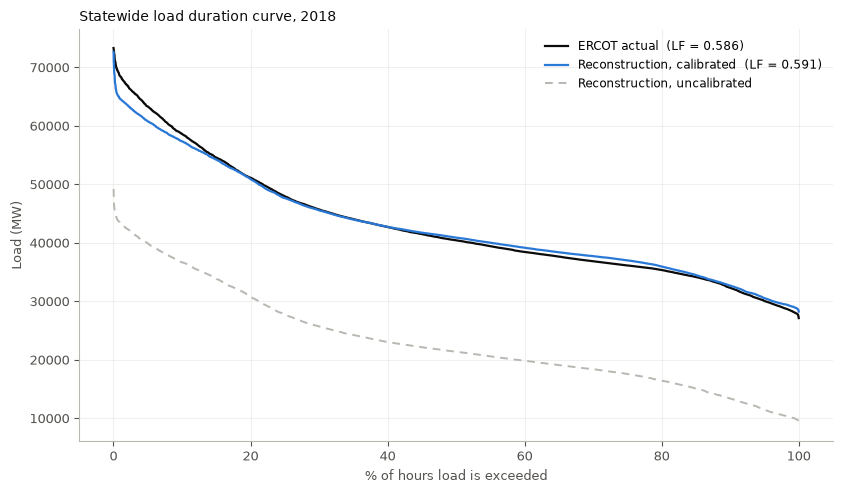

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 5))
pct = np.arange(1, len(y_actual) + 1) / len(y_actual) * 100
ax.plot(pct, np.sort(y_actual.values)[::-1], color=INK, lw=1.6,
        label=f"ERCOT actual  (LF = {y_actual.mean()/y_actual.max():.3f})")
ax.plot(pct, np.sort(stack.values)[::-1], color=BLUE, lw=1.6,
        label=f"Reconstruction, calibrated  (LF = {stack.mean()/stack.max():.3f})")
ax.plot(pct, np.sort((res_bus.sum(axis=1) + com_bus.sum(axis=1)).values)[::-1],
        color=MUTED, lw=1.4, ls=(0, (4, 3)), label="Reconstruction, uncalibrated")
ax.set_xlabel("% of hours load is exceeded"); ax.set_ylabel("Load (MW)")
ax.set_title("Statewide load duration curve, 2018", fontsize=10, color=INK, loc="left")
ax.grid(True, alpha=.6); ax.set_axisbelow(True); ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG / "statewide_ldc_fig1.png", dpi=200); plt.show()


#### 4. Diurnal shape, weekday/weekend $\times$ summer/winter

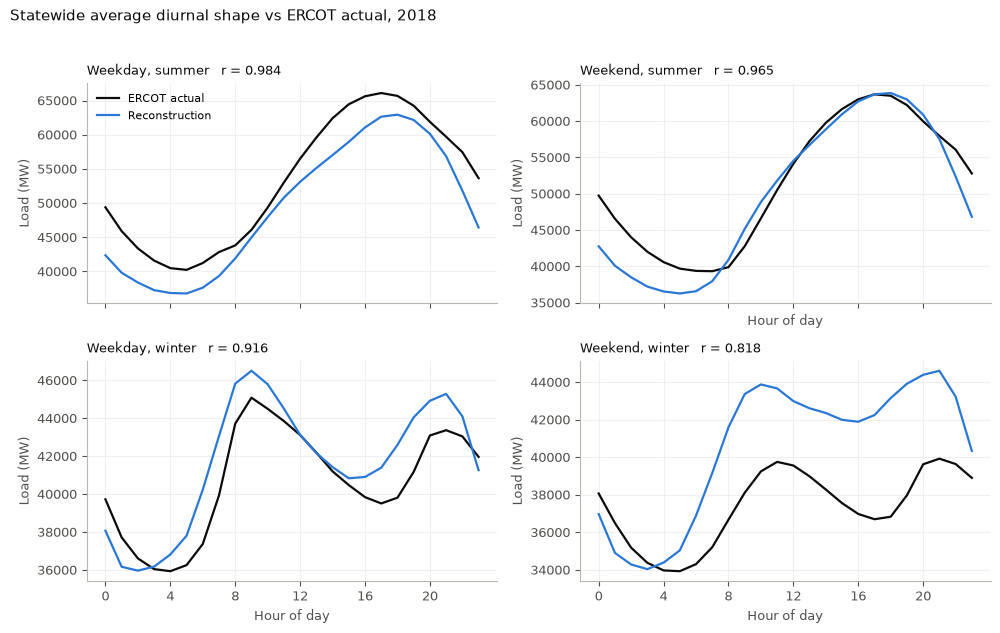

Weekday, summer    0.9837
Weekend, summer    0.9649
Weekday, winter    0.9157
Weekend, winter    0.8181


In [6]:
def diurnal_profile(series, weekday, summer):
    i = series.index
    season = i.month.isin([6, 7, 8]) if summer else i.month.isin([12, 1, 2])
    day = (i.dayofweek < 5) if weekday else (i.dayofweek >= 5)
    sub = series[season & day]
    return sub.groupby(sub.index.hour).mean()


configs = [(True, True, "Weekday, summer"), (False, True, "Weekend, summer"),
           (True, False, "Weekday, winter"), (False, False, "Weekend, winter")]

fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True)
diurnal_rows = {}
for ax, (wd, sm, title) in zip(axes.flat, configs):
    a = diurnal_profile(y_actual, wd, sm)
    m = diurnal_profile(stack, wd, sm)
    diurnal_rows[title] = a.corr(m)
    ax.plot(a.index, a.values, color=INK, lw=1.6, label="ERCOT actual")
    ax.plot(m.index, m.values, color=BLUE, lw=1.6, label="Reconstruction")
    ax.set_title(f"{title}   r = {a.corr(m):.3f}", fontsize=9.5, color=INK, loc="left")
    ax.grid(True, alpha=.6); ax.set_axisbelow(True)
    ax.set_xlabel("Hour of day" if not wd or not sm else "")
    ax.set_ylabel("Load (MW)")
axes.flat[0].legend(frameon=False, fontsize=8)
axes.flat[0].set_xticks(range(0, 24, 4))
fig.suptitle("Statewide average diurnal shape vs ERCOT actual, 2018",
             fontsize=10.5, color=INK, x=.006, ha="left")
fig.tight_layout(rect=[0, 0, 1, .96])
fig.savefig(FIG / "statewide_diurnal_fig1.png", dpi=200); plt.show()
pd.Series(diurnal_rows, name="diurnal_shape_r").to_csv(metrics_dir / "statewide_diurnal_corr.csv")
print(pd.Series(diurnal_rows).round(4).to_string())


#### 5. Seasonal (monthly) bias

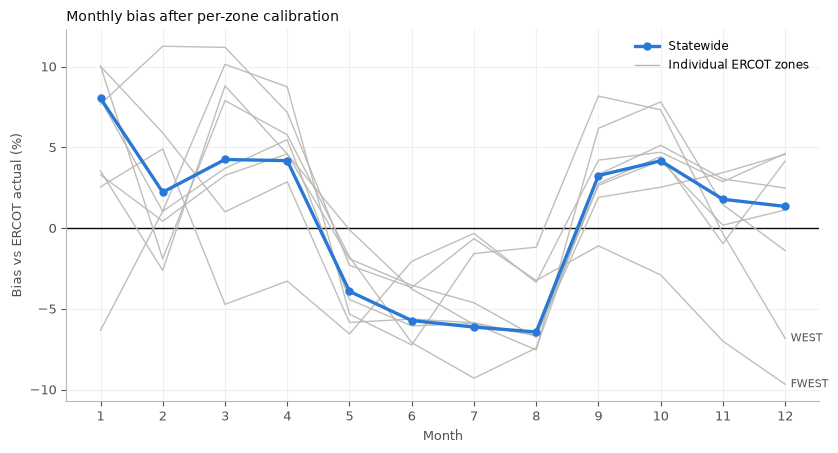

Statewide monthly bias: min -6.4% (month 8), max +8.0% (month 1), mean abs 4.3%


In [7]:
monthly_actual = y_actual.groupby(y_actual.index.month).mean()
monthly_model = stack.groupby(stack.index.month).mean()
bias = (monthly_model / monthly_actual - 1) * 100

zone_bias = {}
for z in ZONES:
    cols = bus_ercot[bus_ercot == z].index.intersection(res_cal.columns)
    pred = res_cal[cols].sum(axis=1) + com_cal[cols].sum(axis=1) + ind_by_zone[z]
    zone_bias[z] = (pred.groupby(pred.index.month).mean()
                    / ercot[z].groupby(ercot.index.month).mean() - 1) * 100
zone_bias = pd.DataFrame(zone_bias)
zone_bias["STATEWIDE"] = bias
zone_bias.index.name = "Month"
zone_bias.to_csv(metrics_dir / "statewide_monthly_bias.csv")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.axhline(0, color=INK, lw=1)
for z in ZONES:
    ax.plot(zone_bias.index, zone_bias[z], color=MUTED, lw=1, alpha=.9)
ax.plot(bias.index, bias.values, color=BLUE, lw=2.4, marker="o", ms=5, label="Statewide")
for z, lab_y in [("FWEST", zone_bias["FWEST"].iloc[-1]), ("WEST", zone_bias["WEST"].iloc[-1])]:
    ax.annotate(z, (12, lab_y), fontsize=8, color=INK2, va="center", xytext=(4, 0),
                textcoords="offset points")
ax.plot([], [], color=MUTED, lw=1, label="Individual ERCOT zones")
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month")
ax.set_ylabel("Bias vs ERCOT actual (%)")
ax.set_title("Monthly bias after per-zone calibration", fontsize=10, color=INK, loc="left")
ax.grid(True, alpha=.6); ax.set_axisbelow(True); ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG / "statewide_monthly_bias_fig1.png", dpi=200); plt.show()
print(f"Statewide monthly bias: min {bias.min():+.1f}% (month {bias.idxmin()}), "
      f"max {bias.max():+.1f}% (month {bias.idxmax()}), mean abs {bias.abs().mean():.1f}%")


#### 6. Spatial consistency proxy

Per-bus annual energy against the per-bus driver (dwellings for residential, floor space for
commercial). Coast reported 0.9479 / 0.8917 on 200 buses; this is the same check on 6,717.

In [8]:
counts = pd.read_csv(statewide_dir / "bus_building_counts_statewide.csv", index_col=0)
arch = [c for c in counts.columns if c not in ("iecc_zone", "COUNTYFP", "Area_Name")]
units = counts[arch].sum(axis=1)
units.index = units.index.astype(str)

sqft = pd.concat([pd.read_csv(exports_out_dir / f"bus_commercial_sqft_{z}.csv", index_col=0)
                  for z in ["2A", "2B", "3A", "3B", "4B"]])
sqft = sqft.sum(axis=1)
sqft.index = sqft.index.astype(str)

res_energy = res_bus.sum(axis=0)
com_energy = com_bus.sum(axis=0)
r_corr = res_energy.corr(units.reindex(res_energy.index).fillna(0))
c_corr = com_energy.corr(sqft.reindex(com_energy.index).fillna(0))
print(f"Spatial consistency proxy, {len(res_energy)} buses:")
print(f"  residential annual energy vs dwellings   r = {r_corr:.4f}   (Coast, 200 buses: 0.9479)")
print(f"  commercial  annual energy vs floor space r = {c_corr:.4f}   (Coast, 200 buses: 0.8917)")
pd.Series({"residential": r_corr, "commercial": c_corr},
          name="spatial_proxy_r").to_csv(metrics_dir / "statewide_spatial_proxy.csv")


Spatial consistency proxy, 6717 buses:
  residential annual energy vs dwellings   r = 0.9729   (Coast, 200 buses: 0.9479)
  commercial  annual energy vs floor space r = 0.9705   (Coast, 200 buses: 0.8917)


#### Summary

Every Coast-level validation metric from review point 5 now exists statewide, saved under
`statewide/metrics/` and plotted into `latex_report/figures/`.